# Soluciones de los ejercicios
### Árboles de Decisión para Series de Tiempo (`Arboles_Clase.ipynb`)

La primera celda reconstruye los objetos de la clase (datos, tabla de rezagos, división y modelo elegido) para que este notebook se pueda ejecutar de forma independiente.

In [1]:
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import root_mean_squared_error, r2_score
from skforecast.recursive import ForecasterRecursive
from skforecast.direct import ForecasterDirect
from skforecast.model_selection import TimeSeriesFold, backtesting_forecaster
from skforecast.exceptions import IgnoredArgumentWarning
import shap

warnings.filterwarnings("ignore", category=IgnoredArgumentWarning)
plt.rcParams["figure.figsize"] = (10, 4)
SEMILLA = 123

def evaluar(y_real, y_pred):
    return {"RECM": root_mean_squared_error(y_real, y_pred), "R2": r2_score(y_real, y_pred)}

# Datos
pm25 = pd.read_csv("d-Shanghai-1317.txt", header=None, names=["PM25"])["PM25"]
pm25.index = pd.date_range(start="2013-01-01", periods=len(pm25), freq="D")

# Tabla de rezagos
LAGS = list(range(1, 11)) + list(range(364, 371))
VENTANA = max(LAGS)
datos = pd.DataFrame(index=pm25.index)
for k in LAGS:
    datos[f"lag_{k}"] = pm25.shift(k)
datos["y"] = pm25
datos = datos.iloc[VENTANA:]
X, y = datos.drop(columns="y"), datos["y"]

# División 70 / 10 / 20
n = len(datos); n_train = int(n * 0.70); n_val = int(n * 0.10); n_test = n - n_train - n_val
X_train, y_train = X.iloc[:n_train], y.iloc[:n_train]
X_val,   y_val   = X.iloc[n_train:n_train + n_val], y.iloc[n_train:n_train + n_val]
X_test,  y_test  = X.iloc[n_train + n_val:], y.iloc[n_train + n_val:]
X_train_val, y_train_val = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
y_hasta_val = pm25.iloc[:VENTANA + n_train + n_val]

# Hiperparámetros elegidos en la clase (sección 4)
MEJOR_PROF = 4
arbol_completo = DecisionTreeRegressor(random_state=SEMILLA).fit(X_train, y_train)
alphas = arbol_completo.cost_complexity_pruning_path(X_train, y_train).ccp_alphas[:-1]
recm_val = [root_mean_squared_error(y_val, DecisionTreeRegressor(ccp_alpha=a, random_state=SEMILLA).fit(X_train, y_train).predict(X_val))
            for a in alphas]
MEJOR_ALPHA = alphas[np.argmin(recm_val)]

arbol_final = DecisionTreeRegressor(max_depth=MEJOR_PROF, random_state=SEMILLA).fit(X_train_val, y_train_val)
pred_test_manual = arbol_final.predict(X_test)
print(f"MEJOR_PROF = {MEJOR_PROF} | MEJOR_ALPHA = {MEJOR_ALPHA:.3f} | RECM prueba = {evaluar(y_test, pred_test_manual)['RECM']:.3f}")

MEJOR_PROF = 4 | MEJOR_ALPHA = 7.855 | RECM prueba = 23.944


---
## Ejercicio 1. Welch y el ciclo anual

El método de Welch divide la serie en segmentos de longitud `nperseg`, calcula el periodograma de cada uno y los promedia. Así reduce el ruido, pero **un segmento de longitud `nperseg` no puede contener un ciclo más largo que él mismo**: el mayor periodo que se puede detectar es `nperseg` días.

nperseg= 256: periodo máximo detectable = 256 días | periodo con mayor potencia = 256.0 días
nperseg=1024: periodo máximo detectable = 1024 días | periodo con mayor potencia = 341.3 días


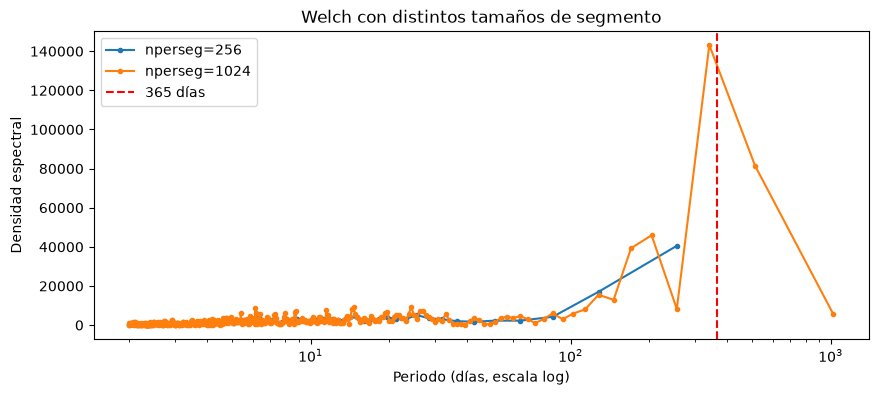

In [2]:
fig, ax = plt.subplots(figsize=(10, 4))
for nperseg in [256, 1024]:
    f_w, p_w = signal.welch(pm25.values, nperseg=nperseg)
    f_w, p_w = f_w[1:], p_w[1:]
    print(f"nperseg={nperseg:4d}: periodo máximo detectable = {1 / f_w[0]:.0f} días | "
          f"periodo con mayor potencia = {1 / f_w[np.argmax(p_w)]:.1f} días")
    ax.semilogx(1 / f_w, p_w, marker=".", label=f"nperseg={nperseg}")
ax.axvline(365, color="red", ls="--", label="365 días")
ax.set_xlabel("Periodo (días, escala log)"); ax.set_ylabel("Densidad espectral"); ax.legend()
ax.set_title("Welch con distintos tamaños de segmento"); plt.show()

**Conclusión.** Con `nperseg=256` el periodo más largo que Welch puede ver es 256 días, así que el ciclo anual es **invisible**: la potencia de ese ciclo se acumula en el primer punto (256 días), que aparece como el "pico". Con `nperseg=1024` el ciclo anual cabe en cada segmento y la potencia máxima aparece en periodos cercanos a un año (la resolución es gruesa: solo se evalúan periodos 1024, 512, 341, 256, …). Por eso, para detectar estacionalidad anual en datos diarios, el periodograma completo (o Welch con segmentos largos) es más adecuado.

---
## Ejercicio 2. Función `crear_rezagos`

In [3]:
def crear_rezagos(serie, lags):
    # Convierte una serie en una tabla supervisada: X con columnas lag_k y y = serie en t.
    tabla = pd.DataFrame(index=serie.index)
    for k in lags:
        tabla[f"lag_{k}"] = serie.shift(k)
    tabla = tabla.iloc[max(lags):]                 # elimina las filas incompletas
    return tabla, serie.iloc[max(lags):]

In [4]:
X_fun, y_fun = crear_rezagos(pm25, LAGS)
X_sk, y_sk = ForecasterRecursive(estimator=DecisionTreeRegressor(), lags=LAGS).create_train_X_y(pm25)

print("Mismas columnas:", list(X_fun.columns) == list(X_sk.columns))
print("Misma X:        ", np.allclose(X_fun.values, X_sk.values))
print("Misma y:        ", np.allclose(y_fun.values, y_sk.values))
print("Sin NaN:        ", not X_fun.isna().any().any())

Mismas columnas: True
Misma X:         True
Misma y:         True
Sin NaN:         True


También funciona con otros rezagos, por ejemplo `[1, 2, 7]`:

In [5]:
X_fun2, _ = crear_rezagos(pm25, [1, 2, 7])
X_sk2, _ = ForecasterRecursive(estimator=DecisionTreeRegressor(), lags=[1, 2, 7]).create_train_X_y(pm25)
print("Misma X con lags [1, 2, 7]:", np.allclose(X_fun2.values, X_sk2.values))

Misma X con lags [1, 2, 7]: True


---
## Ejercicio 3. Validación cruzada con ventana deslizante

Con **ventana creciente** cada pliegue entrena con todo el pasado disponible. Con **ventana deslizante** el entrenamiento tiene siempre el mismo tamaño (368 filas): al avanzar, se agrega el bloque nuevo y se descartan los datos más antiguos.

| | scikit-learn | skforecast |
|---|---|---|
| Ventana creciente | `TimeSeriesSplit(n_splits=5, test_size=100)` | `fixed_train_size=False` |
| Ventana deslizante | `TimeSeriesSplit(n_splits=5, test_size=100, max_train_size=368)` | `fixed_train_size=True` |

In [6]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error
from skforecast.model_selection import grid_search_forecaster

def ecm_por_profundidad(pliegues, profundidades=range(1, 16)):
    # ECM promedio de los pliegues para cada max_depth
    return pd.Series({d: np.mean([mean_squared_error(y_train.iloc[i_va],
                                                     DecisionTreeRegressor(max_depth=d, random_state=SEMILLA)
                                                     .fit(X_train.iloc[i_tr], y_train.iloc[i_tr]).predict(X_train.iloc[i_va]))
                                  for i_tr, i_va in pliegues])
                      for d in profundidades})

pliegues_crec = list(TimeSeriesSplit(n_splits=5, test_size=100).split(X_train))
pliegues_desl = list(TimeSeriesSplit(n_splits=5, test_size=100, max_train_size=368).split(X_train))
print("Filas de entrenamiento por pliegue (creciente): ", [len(i_tr) for i_tr, _ in pliegues_crec])
print("Filas de entrenamiento por pliegue (deslizante):", [len(i_tr) for i_tr, _ in pliegues_desl])

ecm_crec = ecm_por_profundidad(pliegues_crec)
ecm_desl = ecm_por_profundidad(pliegues_desl)
comparacion_cv = pd.DataFrame({"RECM creciente": np.sqrt(ecm_crec), "RECM deslizante": np.sqrt(ecm_desl)})
comparacion_cv.index.name = "max_depth"
print("Mejor max_depth (creciente): ", ecm_crec.idxmin())
print("Mejor max_depth (deslizante):", ecm_desl.idxmin())
comparacion_cv.round(2)

Filas de entrenamiento por pliegue (creciente):  [368, 468, 568, 668, 768]
Filas de entrenamiento por pliegue (deslizante): [368, 368, 368, 368, 368]


Mejor max_depth (creciente):  2
Mejor max_depth (deslizante): 2


,RECM creciente,RECM deslizante
max_depth,,
1,28.88,28.32
2,27.99,28.03
3,28.29,28.37
4,29.07,29.55
5,29.07,29.94
6,30.32,31.32
7,31.77,32.18
8,31.94,32.06
9,32.54,31.90


In [7]:
resultados_desl_sk = grid_search_forecaster(
    forecaster=ForecasterRecursive(estimator=DecisionTreeRegressor(random_state=SEMILLA), lags=LAGS),
    y=pm25.iloc[:VENTANA + n_train],
    cv=TimeSeriesFold(steps=1, initial_train_size=VENTANA + 368, refit=100, fixed_train_size=True),
    param_grid={"max_depth": list(range(1, 16))},
    metric="mean_squared_error",
    return_best=False,
    n_jobs=1,
    show_progress=False,
)
ecm_desl_sk = resultados_desl_sk.set_index("max_depth")["mean_squared_error"].sort_index()
print("Mismo ECM que el manual (deslizante):", np.allclose(ecm_desl_sk.values, ecm_desl.values))
print("Misma profundidad elegida:           ", resultados_desl_sk.iloc[0]["max_depth"] == ecm_desl.idxmin())

Mismo ECM que el manual (deslizante): True
Misma profundidad elegida:            True


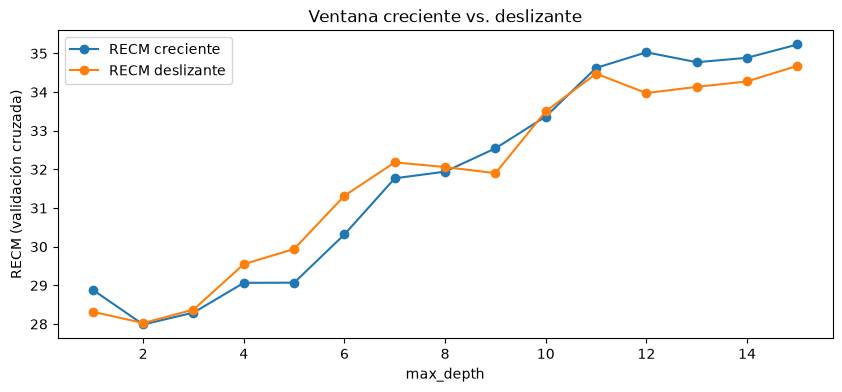

In [8]:
ax = comparacion_cv.plot(marker="o")
ax.set_ylabel("RECM (validación cruzada)"); ax.set_title("Ventana creciente vs. deslizante")
plt.show()

**Conclusión.**

- Ambos esquemas eligen la **misma profundidad** y sus curvas son muy parecidas: en este periodo, descartar los datos antiguos no cambia la decisión.
- La equivalencia entre scikit-learn y `skforecast` se mantiene: `max_train_size=368` corresponde a `fixed_train_size=True`.

**¿Cuándo usar cada uno?**

- **Ventana creciente:** cuando la relación entre el pasado y el presente es estable. Más datos dan árboles más estables.
- **Ventana deslizante:** cuando la serie **cambia con el tiempo** (por ejemplo, nuevas regulaciones ambientales que bajan el nivel de contaminación). Los datos antiguos dejan de ser representativos y pueden empeorar el modelo. Además, todos los pliegues se entrenan con la misma cantidad de datos, lo que hace más comparables sus errores.

---
## Ejercicio 4. `min_samples_leaf` y el límite de los árboles

**(a)** `min_samples_leaf` exige un número mínimo de observaciones en cada hoja. Es otra forma de controlar la complejidad: hojas con más datos dan promedios más estables.

In [9]:
resultados_hoja = []
for m in [1, 5, 10, 20, 50, 100]:
    arbol_m = DecisionTreeRegressor(min_samples_leaf=m, random_state=SEMILLA).fit(X_train, y_train)
    resultados_hoja.append({"min_samples_leaf": m,
                            "RECM_entrenamiento": root_mean_squared_error(y_train, arbol_m.predict(X_train)),
                            "RECM_validación": root_mean_squared_error(y_val, arbol_m.predict(X_val)),
                            "profundidad": arbol_m.get_depth(), "hojas": arbol_m.get_n_leaves()})
resultados_hoja = pd.DataFrame(resultados_hoja).set_index("min_samples_leaf")
MEJOR_HOJA = resultados_hoja["RECM_validación"].idxmin()
print("Mejor min_samples_leaf:", MEJOR_HOJA)
resultados_hoja.round(3)

Mejor min_samples_leaf: 50


,RECM_entrenamiento,RECM_validación,profundidad,hojas
min_samples_leaf,,,,
1,0.000,22.451,27,865
5,15.484,18.522,17,145
10,19.472,18.078,12,68
20,22.250,15.539,8,31
50,24.187,14.405,5,13
100,25.205,15.760,3,7


In [10]:
arbol_hoja = DecisionTreeRegressor(min_samples_leaf=MEJOR_HOJA, random_state=SEMILLA).fit(X_train, y_train)
arbol_prof = DecisionTreeRegressor(max_depth=MEJOR_PROF, random_state=SEMILLA).fit(X_train, y_train)
pd.DataFrame({f"max_depth={MEJOR_PROF}": {**evaluar(y_val, arbol_prof.predict(X_val)), "hojas": arbol_prof.get_n_leaves()},
              f"min_samples_leaf={MEJOR_HOJA}": {**evaluar(y_val, arbol_hoja.predict(X_val)), "hojas": arbol_hoja.get_n_leaves()}}).round(3)

,max_depth=4,min_samples_leaf=50
RECM,14.551,14.405
R2,0.310,0.324
hojas,16.000,13.000


Ambas restricciones reducen el sobreajuste del árbol completo (`min_samples_leaf=1`). La comparación se hace siempre en **validación**.

**(b)** Valor máximo observado vs. valor máximo que puede predecir el árbol final:

In [11]:
max_hojas = arbol_final.tree_.value[arbol_final.apply(X_train_val)].max()
print(f"Máximo de y en entrenamiento+validación: {y_train_val.max():.1f}")
print(f"Máximo valor que puede predecir el árbol (hoja más alta): {max_hojas:.1f}")
print(f"Máximo de y en prueba: {y_test.max():.1f}  |  máximo predicho en prueba: {pred_test_manual.max():.1f}")

Máximo de y en entrenamiento+validación: 221.0
Máximo valor que puede predecir el árbol (hoja más alta): 162.1
Máximo de y en prueba: 155.8  |  máximo predicho en prueba: 117.3


**Conclusión.** La predicción de un árbol es siempre el promedio de una hoja, así que **nunca supera el promedio de la hoja más alta**, que es mucho menor que el máximo observado. En días de contaminación extrema el árbol subestimará sistemáticamente: no puede extrapolar.

---
## Ejercicio 5. Verificación manual vs. `skforecast` para el árbol podado

In [12]:
forecaster_podado = ForecasterRecursive(
    estimator=DecisionTreeRegressor(ccp_alpha=MEJOR_ALPHA, random_state=SEMILLA),
    lags=LAGS,
)

# Verificación 2: validación
cv_val = TimeSeriesFold(steps=1, initial_train_size=VENTANA + n_train, refit=False)
_, pred_val_sk = backtesting_forecaster(forecaster_podado, y=y_hasta_val, cv=cv_val,
                                        metric="mean_squared_error", n_jobs=1, show_progress=False)
podado_train = DecisionTreeRegressor(ccp_alpha=MEJOR_ALPHA, random_state=SEMILLA).fit(X_train, y_train)
print("Validación igual:", np.allclose(pred_val_sk["pred"].values, podado_train.predict(X_val)))

# Verificación 4: prueba
cv_test = TimeSeriesFold(steps=1, initial_train_size=VENTANA + n_train + n_val, refit=False)
_, pred_test_sk = backtesting_forecaster(forecaster_podado, y=pm25, cv=cv_test,
                                         metric="mean_squared_error", n_jobs=1, show_progress=False)
podado_train_val = DecisionTreeRegressor(ccp_alpha=MEJOR_ALPHA, random_state=SEMILLA).fit(X_train_val, y_train_val)
print("Prueba igual:    ", np.allclose(pred_test_sk["pred"].values, podado_train_val.predict(X_test)))

Validación igual: True


Prueba igual:     True


**Conclusión.** La equivalencia no depende del hiperparámetro: con la misma tabla de rezagos, la misma semilla y los mismos datos de entrenamiento, `skforecast` entrena exactamente el mismo árbol que el procedimiento manual.

---
## Ejercicio 6. Explicar el día con mayor error

Fecha: 2016-12-15 | observado: 155.8 | predicho: 64.1 | error: 91.7
PM2.5 en los días previos (lag_1, lag_2, lag_3): [72.8, 25.5, 39.5]


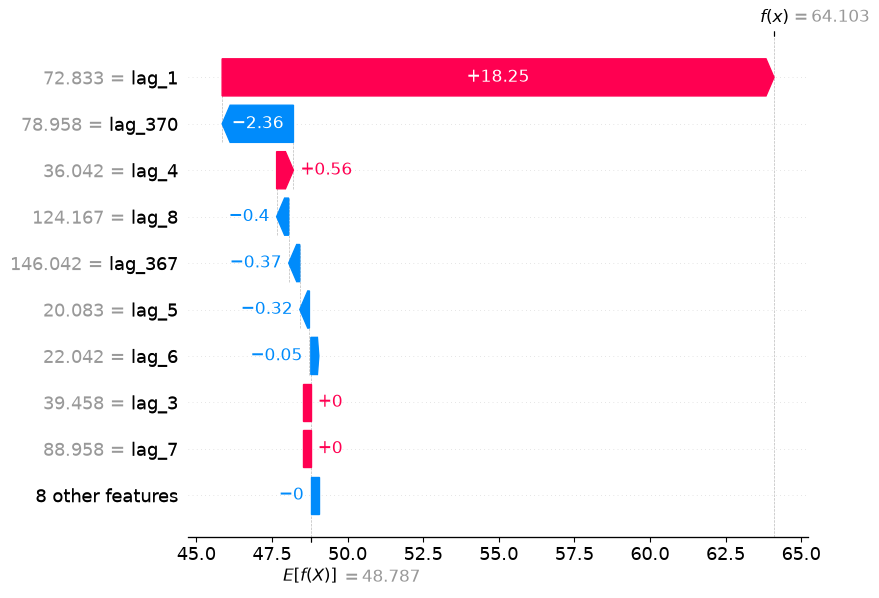

In [13]:
explicador = shap.TreeExplainer(arbol_final)
shap_test = explicador(X_test)

errores = np.abs(y_test.values - pred_test_manual)
i_err = int(np.argmax(errores))
print(f"Fecha: {y_test.index[i_err].date()} | observado: {y_test.iloc[i_err]:.1f} | "
      f"predicho: {pred_test_manual[i_err]:.1f} | error: {errores[i_err]:.1f}")
print(f"PM2.5 en los días previos (lag_1, lag_2, lag_3): {X_test.iloc[i_err][['lag_1', 'lag_2', 'lag_3']].round(1).tolist()}")
shap.plots.waterfall(shap_test[i_err], max_display=10)

/var/folders/mk/ddcwt6qx1zs7k1kft5fdrnf40000gn/T/ipykernel_28577/3714707968.py:3: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  rango = slice(fecha_err - pd.Timedelta(days=15), fecha_err + pd.Timedelta(days=5))


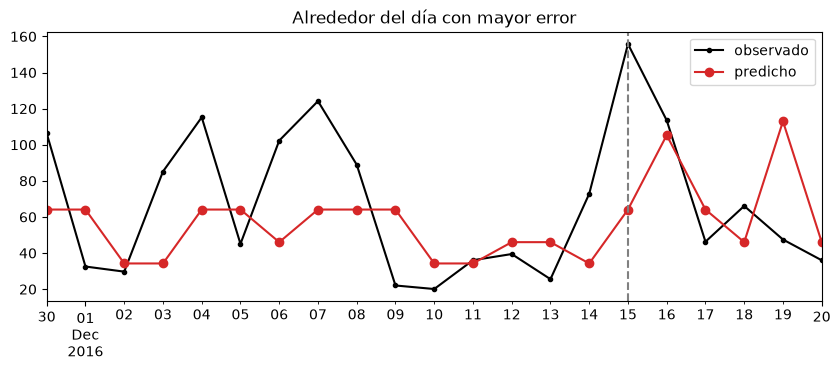

In [14]:
fig, ax = plt.subplots(figsize=(10, 3.5))
fecha_err = y_test.index[i_err]
rango = slice(fecha_err - pd.Timedelta(days=15), fecha_err + pd.Timedelta(days=5))
y_test[rango].plot(ax=ax, color="black", marker=".", label="observado")
pd.Series(pred_test_manual, index=y_test.index)[rango].plot(ax=ax, color="tab:red", marker="o", label="predicho")
ax.axvline(fecha_err, color="gray", ls="--"); ax.legend(); ax.set_title("Alrededor del día con mayor error")
plt.show()

**Cómo interpretar.** El *waterfall* parte del valor base (el promedio de entrenamiento+validación) y suma las contribuciones de cada variable. En el día con mayor error:

- `lag_1` (el PM2.5 del día anterior, alto respecto al promedio) es casi la única variable que actúa: **sube** la predicción unos 18 µg/m³. Las demás aportan muy poco.
- Aun así, la predicción queda muy por debajo del valor observado: el salto de ese día **no estaba anunciado en los rezagos** (los días previos tenían valores moderados).
- Además, la predicción no podría superar el promedio de la hoja más alta (ejercicio 4b).

 Los cambios bruscos de contaminación suelen depender de factores externos (viento, lluvia, emisiones) que el modelo no conoce: es una motivación para incluir **variables exógenas**.

---
## Ejercicio 7. Pronóstico 3 pasos adelante

Partimos del final del conjunto de validación (último dato: fin de validación) y pronosticamos los 3 primeros días de prueba.

### (a) Recursivo a mano

In [15]:
H = 3
historia = list(y_hasta_val.values)        # valores observados hasta el final de validación
pred_rec_manual = []
for h in range(H):
    fila = pd.DataFrame([[historia[-k] for k in LAGS]], columns=X.columns)   # lag_k = valor k posiciones atrás
    p = arbol_final.predict(fila)[0]
    pred_rec_manual.append(p)
    historia.append(p)                     # la predicción pasa a ser parte de la historia

forecaster_rec = ForecasterRecursive(estimator=DecisionTreeRegressor(max_depth=MEJOR_PROF, random_state=SEMILLA), lags=LAGS)
forecaster_rec.fit(y=y_hasta_val)
pred_rec_sk = forecaster_rec.predict(steps=H)

print("Manual:    ", np.round(pred_rec_manual, 4))
print("skforecast:", np.round(pred_rec_sk.values, 4))
print("Iguales:   ", np.allclose(pred_rec_manual, pred_rec_sk.values))

Manual:     [34.2434 46.0436 46.0436]
skforecast: [34.2434 46.0436 46.0436]
Iguales:    True


### (b) Directo a mano

En la tabla, la fila del día $t$ tiene rezagos hasta $t-1$ y respuesta $y_t$ (horizonte 1). Para el horizonte $h$ queremos, con esos mismos rezagos, predecir $y_{t+h-1}$: basta **desplazar la respuesta $h-1$ filas hacia arriba**.

**Detalle importante para que coincida con `skforecast`:** al desplazar la respuesta, las últimas filas se quedan sin respuesta (para $h=3$ faltan 2). `ForecasterDirect` entrena **todos** los modelos con las **mismas filas** (fechas), así que descarta las últimas $H-1$ filas también para los horizontes 1 y 2. Si cada modelo usara todas las filas disponibles, el resultado sería un poco distinto: se probó y el pronóstico a 1 día cambia de 34.26 a 34.24.

Los tres modelos usan la **misma fila de entrada**: los rezagos observados del primer día de prueba.

In [16]:
x_entrada = X_test.iloc[[0]]               # rezagos observados al final de validación
m = len(X_train_val) - (H - 1)            # filas comunes a los H modelos
pred_dir_manual = []
for h in range(1, H + 1):
    X_h = X_train_val.iloc[:m]
    y_h = y_train_val.iloc[h - 1:h - 1 + m]   # respuesta desplazada h-1 filas
    modelo_h = DecisionTreeRegressor(max_depth=MEJOR_PROF, random_state=SEMILLA).fit(X_h, y_h.values)
    pred_dir_manual.append(modelo_h.predict(x_entrada)[0])

forecaster_dir = ForecasterDirect(estimator=DecisionTreeRegressor(max_depth=MEJOR_PROF, random_state=SEMILLA),
                                  lags=LAGS, steps=H, n_jobs=1)
forecaster_dir.fit(y=y_hasta_val)
pred_dir_sk = forecaster_dir.predict()

print("Manual:    ", np.round(pred_dir_manual, 4))
print("skforecast:", np.round(pred_dir_sk.values, 4))
print("Iguales:   ", np.allclose(pred_dir_manual, pred_dir_sk.values))

Manual:     [34.2618 30.0262 36.5972]
skforecast: [34.2618 30.0262 36.5972]
Iguales:    True


In [17]:
pd.DataFrame({"observado": pm25.loc[pred_rec_sk.index].values,
              "recursivo": pred_rec_sk.values,
              "directo": pred_dir_sk.values}, index=pred_rec_sk.index).round(2)

,observado,recursivo,directo
2016-09-24,27.50,34.24,34.26
2016-09-25,17.71,46.04,30.03
2016-09-26,11.04,46.04,36.60


### (c) Backtesting con `steps=3` vs. `steps=1` en el conjunto de prueba

Con `steps=3`, cada partición pronostica 3 días seguidos (recursivamente) y luego avanza 3 días incorporando los valores reales.

In [18]:
cv_test = TimeSeriesFold(steps=1, initial_train_size=VENTANA + n_train + n_val, refit=False)
cv_test3 = TimeSeriesFold(steps=3, initial_train_size=VENTANA + n_train + n_val, refit=False)

_, pred_1 = backtesting_forecaster(forecaster_rec, y=pm25, cv=cv_test, metric="mean_squared_error", n_jobs=1, show_progress=False)
_, pred_3 = backtesting_forecaster(forecaster_rec, y=pm25, cv=cv_test3, metric="mean_squared_error", n_jobs=1, show_progress=False)

# Error por horizonte dentro de cada bloque de 3 días
pred_3["horizonte"] = np.tile([1, 2, 3], len(pred_3) // 3 + 1)[:len(pred_3)]
pred_3["real"] = pm25.loc[pred_3.index]
recm_h = pd.Series({h: root_mean_squared_error(d["real"], d["pred"]) for h, d in pred_3.groupby("horizonte")}, name="RECM")
recm_h.index.name = "horizonte"

print(f"RECM steps=1: {root_mean_squared_error(pm25.loc[pred_1.index], pred_1['pred']):.3f}")
print(f"RECM steps=3: {root_mean_squared_error(pred_3['real'], pred_3['pred']):.3f}")
print("\nRECM según el horizonte dentro del bloque de 3 días:")
print(recm_h.round(3).to_string())

RECM steps=1: 23.944
RECM steps=3: 28.399

RECM según el horizonte dentro del bloque de 3 días:
horizonte
1    24.089
2    30.896
3    29.742


**Conclusión.** El error **aumenta al pasar del paso 1 a los pasos 2 y 3** (entre los pasos 2 y 3 la diferencia es pequeña, porque el pronóstico ya se aplanó). En el paso 1 el modelo usa el valor real de ayer, la variable más informativa. En los pasos 2 y 3 ese valor se reemplaza por una predicción, que ya tiene error y además es un promedio de hoja (menos variable que el dato real). Los errores se **propagan** y el pronóstico tiende hacia valores típicos (aplanamiento).

---
## Ejercicio 8. Actualizar la ventana sin reentrenar

Para pronosticar un día se necesitan los últimos `VENTANA` = 370 valores (el rezago más largo). Cuando llega un dato nuevo, se agrega al final y se descarta el más antiguo; el modelo **no se reentrena**.

In [19]:
forecaster_produccion = ForecasterRecursive(estimator=DecisionTreeRegressor(max_depth=MEJOR_PROF, random_state=SEMILLA), lags=LAGS)
forecaster_produccion.fit(y=pm25)

fecha_nueva = pm25.index[-1] + pd.Timedelta(days=1)
dato_nuevo = pd.Series([60.0], index=[fecha_nueva])          # valor observado inventado

ventana_actualizada = pd.concat([pm25, dato_nuevo]).iloc[-VENTANA:]
ventana_actualizada.index.freq = "D"
print(f"Longitud de last_window: {len(ventana_actualizada)} | de {ventana_actualizada.index[0].date()} a {ventana_actualizada.index[-1].date()}")

pred_sig = forecaster_produccion.predict(steps=1, last_window=ventana_actualizada)
pred_sig

Longitud de last_window: 370 | de 2016-05-27 a 2017-05-31


/var/folders/mk/ddcwt6qx1zs7k1kft5fdrnf40000gn/T/ipykernel_28577/1273498859.py:4: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  fecha_nueva = pm25.index[-1] + pd.Timedelta(days=1)


2017-06-01    53.564934
Freq: D, Name: pred, dtype: float64

In [20]:
# Verificación a mano con el árbol de producción
arbol_produccion = DecisionTreeRegressor(max_depth=MEJOR_PROF, random_state=SEMILLA).fit(X, y)
fila = pd.DataFrame([[ventana_actualizada.iloc[-k] for k in LAGS]], columns=X.columns)
print("Pronóstico manual:", round(arbol_produccion.predict(fila)[0], 4), "| igual a skforecast:",
      np.isclose(arbol_produccion.predict(fila)[0], pred_sig.iloc[0]))

Pronóstico manual: 53.5649 | igual a skforecast: True


**Conclusión.** `last_window` debe tener al menos **370 valores** (el rezago máximo). En producción es habitual actualizar la ventana a diario y reentrenar el modelo con menor frecuencia (por ejemplo, cada mes), ya que reentrenar es más costoso que predecir.